In [1]:
from typing import Any

import geopandas as gpd
import requests
from shapely.geometry import shape
from shapely.ops import unary_union

In [2]:
from sqlalchemy import create_engine

In [3]:
engine = create_engine(
    "postgresql+psycopg2://cim_wizard_user:cim_wizard_password"
    "@130.192.238.11:15432/cim_wizard_integrated"
)

In [4]:
from pathlib import Path

In [5]:
import pandas as pd
pd.set_option("display.max_columns", None)  # show every column
pd.set_option("display.width", None)        # don't wrap to terminal width
pd.set_option("display.max_colwidth", None)   # widen each column's text (default 50)
pd.set_option("display.max_rows", None)

In [7]:
torino_residenziale_express= pd.read_csv("torino_residenziale_express_archetypes.csv")
torino_residenziale_express.head(1)

,lod0_footprint_4326,lod0_footprint_method,building_id,building_id_method,landuse_category,landuse_category_method,filter_buildings_outof_polygons,filter_buildings_outof_polygons_method,construction_period,construction_period_method,floor_count_raw,floor_count_raw_method,building_height_m,building_height_method,eave_elevation_m,eave_elevation_method,ground_elevation_m,ground_elevation_method,heritage_status,heritage_status_method,name,name_method,addresses,addresses_method,number_of_addresses,number_of_addresses_method,building_size_class,building_size_class_method,building_architype,building_architype_method,archetype_period_id,archetype_class,u_wall,u_wall_method,u_roof,u_roof_method,u_ceiling,u_ceiling_method,u_floor,u_floor_method,u_window,u_window_method,u_door,u_door_method,heating_system_type,heating_system_type_method,energy_carrier,energy_carrier_method,dhw_system,dhw_system_method,refurbished,refurbished_method,refurbishment_type,refurbishment_type_method,cluster_performance_level,cluster_performance_level_method,cluster_window_type,cluster_window_type_method,cluster_heat_generator,cluster_heat_generator_method
0,"POLYGON ((7.647523047185765 45.020758531750445, 7.647662459557006 45.0207148416829, 7.647679471347668 45.02074268749799, 7.6478688332761955 45.0210523393632, 7.647733651367135 45.02109475654008, 7.647523047185765 45.020758531750445))",DBGT,0,DBGT,residenziale,DBGT,EDIFICI PRINCIPALI,DBGT,1971 - 1980,DBGT,6+1,DBGT,25.75,DBGT,264.35,DBGT,238.6,DBGT,non monumentale,DBGT,NaN,DBGT,"['VIA PIACENZA 13', 'VIA PIACENZA 17', 'VIA PIACENZA 15']",civici_202211.csv,3,assign_addresses_to_buildings,MFH,episcope,MFH_05,episcope distribution,P5,MFH,1.1516,episcope distribution,2.2167,episcope distribution,1.6636,episcope distribution,1.3182,episcope distribution,4.9,episcope distribution,NaN,episcope distribution,Central heating system for several dwellings,episcope distribution,Natural gas,episcope distribution,Same system as heating,episcope distribution,True,episcope distribution,technical_systems,episcope distribution,3.0,episcope distribution,Standard double glazing,episcope distribution,District heating,episcope distribution


In [8]:

torino_residenziale_express["lod0_footprint_4326"] = gpd.GeoSeries.from_wkt(
    torino_residenziale_express["lod0_footprint_4326"],
    crs="EPSG:4326",
)

footprints = gpd.GeoSeries(
    torino_residenziale_express["lod0_footprint_4326"],
    crs="EPSG:4326",
)
torino_residenziale_express["lod0_footprint_32632"] = footprints.to_crs("EPSG:32632")

In [9]:
torino_residenziale_express = gpd.GeoDataFrame(
    torino_residenziale_express,
    geometry="lod0_footprint_4326",
    crs="EPSG:4326",
)
torino_residenziale_express.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [9]:
torino_residenziale_express.head(1)

,lod0_footprint_4326,lod0_footprint_method,building_id,building_id_method,landuse_category,landuse_category_method,filter_buildings_outof_polygons,filter_buildings_outof_polygons_method,construction_period,construction_period_method,floor_count_raw,floor_count_raw_method,building_height_m,building_height_method,eave_elevation_m,eave_elevation_method,ground_elevation_m,ground_elevation_method,heritage_status,heritage_status_method,name,name_method,addresses,addresses_method,number_of_addresses,number_of_addresses_method,building_size_class,building_size_class_method,building_architype,building_architype_method,archetype_period_id,archetype_class,u_wall,u_wall_method,u_roof,u_roof_method,u_ceiling,u_ceiling_method,u_floor,u_floor_method,u_window,u_window_method,u_door,u_door_method,heating_system_type,heating_system_type_method,energy_carrier,energy_carrier_method,dhw_system,dhw_system_method,refurbished,refurbished_method,refurbishment_type,refurbishment_type_method,cluster_performance_level,cluster_performance_level_method,cluster_window_type,cluster_window_type_method,cluster_heat_generator,cluster_heat_generator_method,lod0_footprint_32632
0,"POLYGON ((7.64752 45.02076, 7.64766 45.02071, 7.64768 45.02074, 7.64787 45.02105, 7.64773 45.02109, 7.64752 45.02076))",DBGT,0,DBGT,residenziale,DBGT,EDIFICI PRINCIPALI,DBGT,1971 - 1980,DBGT,6+1,DBGT,25.75,DBGT,264.35,DBGT,238.6,DBGT,non monumentale,DBGT,NaN,DBGT,"['VIA PIACENZA 13', 'VIA PIACENZA 17', 'VIA PIACENZA 15']",civici_202211.csv,3,assign_addresses_to_buildings,MFH,episcope,MFH_05,episcope distribution,P5,MFH,1.1516,episcope distribution,2.2167,episcope distribution,1.6636,episcope distribution,1.3182,episcope distribution,4.9,episcope distribution,NaN,episcope distribution,Central heating system for several dwellings,episcope distribution,Natural gas,episcope distribution,Same system as heating,episcope distribution,True,episcope distribution,technical_systems,episcope distribution,3.0,episcope distribution,Standard double glazing,episcope distribution,District heating,episcope distribution,"POLYGON ((393442.617 4986146.114, 393453.52 4986141.077, 393454.912 4986144.148, 393470.405 4986178.298, 393459.834 4986183.188, 393442.617 4986146.114))"


In [10]:
torino_residenziale_express[["building_id", "lod0_footprint_32632"]].head(1)
torino_residenziale_express["lod0_footprint_32632"].crs

<Projected CRS: EPSG:32632>
Name: WGS 84 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 6°E and 12°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Austria. Cameroon. Denmark. Equatorial Guinea. France. Gabon. Germany. Italy. Libya. Liechtenstein. Monaco. Netherlands. Niger. Nigeria. Norway. Sao Tome and Principe. Svalbard. Sweden. Switzerland. Tunisia. Vatican City State.
- bounds: (6.0, 0.0, 12.0, 84.0)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [11]:
torino_residenziale_express["lod0_footprint_32632"] = footprints.to_crs("EPSG:32632")

In [12]:
print(type(torino_residenziale_express["lod0_footprint_32632"].iloc[0]))
torino_residenziale_express["lod0_footprint_32632"].iloc[0].bounds

<class 'shapely.geometry.polygon.Polygon'>


(393442.6170305335, 4986141.077434972, 393470.4053688118, 4986183.187663889)

In [13]:
import numpy as np
import shapely

MIN_EDGE_M = 0.5

ground = pd.to_numeric(torino_residenziale_express["ground_elevation_m"], errors="coerce")
height = pd.to_numeric(torino_residenziale_express["building_height_m"], errors="coerce")
eave = pd.to_numeric(torino_residenziale_express["eave_elevation_m"], errors="coerce")
eave = eave.fillna(ground + height)

parts = gpd.GeoDataFrame(
    {
        "building_id": torino_residenziale_express["building_id"].to_numpy(),
        "z_ground": ground.to_numpy(),
        "z_eave": eave.to_numpy(),
    },
    geometry=gpd.GeoSeries(
        torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
        crs="EPSG:32632",
    ),
)
parts = parts.explode(index_parts=False).reset_index(drop=True)
parts = parts[
    parts.geometry.geom_type.eq("Polygon")
    & parts["z_ground"].notna()
    & parts["z_eave"].notna()
    & (parts["z_eave"] > parts["z_ground"])
].reset_index(drop=True)

# clockwise exterior, counter-clockwise holes, so the left side of each edge is outward
polygons = shapely.normalize(parts.geometry.to_numpy())
rings, ring_part = shapely.get_rings(polygons, return_index=True)
ring_is_hole = pd.Series(ring_part).groupby(ring_part).cumcount().to_numpy() > 0

coords, coord_ring = shapely.get_coordinates(rings, return_index=True)
same_ring = coord_ring[:-1] == coord_ring[1:]
start = coords[:-1][same_ring]
end = coords[1:][same_ring]
ring_index = coord_ring[:-1][same_ring]
part_index = ring_part[ring_index]

dx = end[:, 0] - start[:, 0]
dy = end[:, 1] - start[:, 1]
length = np.hypot(dx, dy)
keep = length >= MIN_EDGE_M

walls = gpd.GeoDataFrame(
    {
        "building_id": parts["building_id"].to_numpy()[part_index[keep]],
        "z_ground": parts["z_ground"].to_numpy()[part_index[keep]],
        "z_eave": parts["z_eave"].to_numpy()[part_index[keep]],
        "is_courtyard": ring_is_hole[ring_index[keep]],
        "length_m": length[keep],
        "azimuth_deg": np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360,
    },
    geometry=shapely.linestrings(np.stack([start[keep], end[keep]], axis=1)),
    crs="EPSG:32632",
)
walls["wall_id"] = walls.groupby("building_id").cumcount()
walls.head()

,building_id,z_ground,z_eave,is_courtyard,length_m,azimuth_deg,geometry,wall_id
0,0,238.6,264.35,False,40.875950,294.909703,"LINESTRING (393442.617 4986146.114, 393459.834 4986183.188)",0
1,0,238.6,264.35,False,11.647925,24.822308,"LINESTRING (393459.834 4986183.188, 393470.405 4986178.298)",1
2,0,238.6,264.35,False,37.499777,114.403756,"LINESTRING (393470.405 4986178.298, 393454.912 4986144.148)",2
3,0,238.6,264.35,False,3.371687,114.383241,"LINESTRING (393454.912 4986144.148, 393453.52 4986141.077)",3
4,0,238.6,264.35,False,12.010051,204.795889,"LINESTRING (393453.52 4986141.077, 393442.617 4986146.114)",4


In [14]:
walls.head(20)

,building_id,z_ground,z_eave,is_courtyard,length_m,azimuth_deg,geometry,wall_id
0,0,238.60,264.35,False,40.875950,294.909703,"LINESTRING (393442.617 4986146.114, 393459.834 4986183.188)",0
1,0,238.60,264.35,False,11.647925,24.822308,"LINESTRING (393459.834 4986183.188, 393470.405 4986178.298)",1
2,0,238.60,264.35,False,37.499777,114.403756,"LINESTRING (393470.405 4986178.298, 393454.912 4986144.148)",2
3,0,238.60,264.35,False,3.371687,114.383241,"LINESTRING (393454.912 4986144.148, 393453.52 4986141.077)",3
4,0,238.60,264.35,False,12.010051,204.795889,"LINESTRING (393453.52 4986141.077, 393442.617 4986146.114)",4
5,1,241.49,263.23,False,11.225564,277.210239,"LINESTRING (395883.517 4995054.229, 395884.926 4995065.366)",0
6,1,241.49,263.23,False,10.797795,6.289557,"LINESTRING (395884.926 4995065.366, 395895.659 4995064.183)",1
7,1,241.49,263.23,False,5.611758,96.918357,"LINESTRING (395895.659 4995064.183, 395894.983 4995058.612)",2
8,1,241.49,263.23,False,2.512924,6.856114,"LINESTRING (395894.983 4995058.612, 395897.478 4995058.312)",3
9,1,241.49,263.23,False,2.674510,97.108832,"LINESTRING (395897.478 4995058.312, 395897.147 4995055.658)",4


In [15]:
walls.crs


<Projected CRS: EPSG:32632>
Name: WGS 84 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 6°E and 12°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Austria. Cameroon. Denmark. Equatorial Guinea. France. Gabon. Germany. Italy. Libya. Liechtenstein. Monaco. Netherlands. Niger. Nigeria. Norway. Sao Tome and Principe. Svalbard. Sweden. Switzerland. Tunisia. Vatican City State.
- bounds: (6.0, 0.0, 12.0, 84.0)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [14]:
walls["is_courtyard"].value_counts()


is_courtyard
False    421933
True        714
Name: count, dtype: int64

In [15]:
walls.geometry.iloc[0].length


40.8759497944847

In [16]:
from collections import defaultdict

from shapely.ops import substring

GAP_M = 0.5
MIN_SHARED_M = 1.0
HEIGHT_TOL_M = 1.0

ground = pd.to_numeric(torino_residenziale_express["ground_elevation_m"], errors="coerce")
height = pd.to_numeric(torino_residenziale_express["building_height_m"], errors="coerce")
eave = pd.to_numeric(torino_residenziale_express["eave_elevation_m"], errors="coerce")
eave = eave.fillna(ground + height)

buildings_m = gpd.GeoDataFrame(
    {
        "building_id": torino_residenziale_express["building_id"].to_numpy(),
        "z_ground": ground.to_numpy(),
        "z_eave": eave.to_numpy(),
    },
    geometry=gpd.GeoSeries(
        torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
        crs="EPSG:32632",
    ),
)
buildings_m = buildings_m[
    buildings_m.geometry.notna()
    & ~buildings_m.geometry.is_empty
    & buildings_m["z_ground"].notna()
    & buildings_m["z_eave"].notna()
].reset_index(drop=True)


def cuts(length, breaks):
    points = [0.0]
    for value in sorted(breaks):
        value = min(max(float(value), 0.0), length)
        if value - points[-1] < 0.05:
            continue
        points.append(value)
    if length - points[-1] < 0.05:
        points[-1] = length
    else:
        points.append(length)
    return points


def vertical_bands(z0, z1, covering):
    party = []
    for n0, n1, neighbor_id in covering:
        lo, hi = max(z0, n0), min(z1, n1)
        if hi <= lo:
            continue
        if 0 <= z1 - hi < HEIGHT_TOL_M:
            hi = z1
        if 0 <= lo - z0 < HEIGHT_TOL_M:
            lo = z0
        if hi - lo < 0.05:
            continue
        party.append((lo, hi, neighbor_id))
    if not party:
        neighbor_id = max(covering, key=lambda item: item[1])[2]
        return [(z0, z1, "exposed_opaque", neighbor_id)]
    party.sort()
    merged = [list(party[0])]
    for lo, hi, neighbor_id in party[1:]:
        if lo > merged[-1][1] + 0.05:
            merged.append([lo, hi, neighbor_id])
        elif hi > merged[-1][1]:
            merged[-1][1] = hi
            merged[-1][2] = neighbor_id
    bands = []
    cursor = z0
    for lo, hi, neighbor_id in merged:
        if lo - cursor >= 0.05:
            bands.append((cursor, lo, "exposed_opaque", neighbor_id))
        bands.append((lo, hi, "party", neighbor_id))
        cursor = hi
    if z1 - cursor >= 0.05:
        bands.append((cursor, z1, "exposed_opaque", merged[-1][2]))
    return bands


tree = shapely.STRtree(buildings_m.geometry.to_numpy())
wall_index, neighbor_index = tree.query(
    walls.geometry.to_numpy(),
    predicate="dwithin",
    distance=GAP_M,
)
different = (
    walls["building_id"].to_numpy()[wall_index]
    != buildings_m["building_id"].to_numpy()[neighbor_index]
)
wall_index = wall_index[different]
neighbor_index = neighbor_index[different]
covered = shapely.intersection(
    walls.geometry.to_numpy()[wall_index],
    shapely.buffer(buildings_m.geometry.to_numpy()[neighbor_index], GAP_M),
)
long_enough = shapely.length(covered) >= MIN_SHARED_M
wall_index = wall_index[long_enough]
neighbor_index = neighbor_index[long_enough]
covered = covered[long_enough]

hits = defaultdict(list)
lines = walls.geometry.to_numpy()
neighbor_ground = buildings_m["z_ground"].to_numpy()
neighbor_eave = buildings_m["z_eave"].to_numpy()
neighbor_ids = buildings_m["building_id"].to_numpy()
for w_i, n_i, geom in zip(wall_index, neighbor_index, covered):
    line = lines[w_i]
    for part in shapely.get_parts(geom):
        if part.geom_type != "LineString":
            continue
        coordinates = shapely.get_coordinates(part)
        lo, hi = sorted((
            float(line.project(shapely.Point(coordinates[0]))),
            float(line.project(shapely.Point(coordinates[-1]))),
        ))
        if hi - lo < MIN_SHARED_M:
            continue
        hits[int(w_i)].append((
            lo, hi,
            float(neighbor_ground[n_i]),
            float(neighbor_eave[n_i]),
            neighbor_ids[n_i],
        ))

building_ids = walls["building_id"].to_numpy()
wall_ids = walls["wall_id"].to_numpy()
courtyard = walls["is_courtyard"].to_numpy()
azimuth = walls["azimuth_deg"].to_numpy()
lengths = walls["length_m"].to_numpy()
z_ground = walls["z_ground"].to_numpy()
z_eave = walls["z_eave"].to_numpy()

rows = []
for i in range(len(walls)):
    length = float(lengths[i])
    z0, z1 = float(z_ground[i]), float(z_eave[i])
    pieces = hits.get(i, [])
    plan = cuts(length, [0.0, length, *[value for piece in pieces for value in piece[:2]]])
    for start, end in zip(plan, plan[1:]):
        mid = (start + end) / 2
        covering = [
            (n0, n1, neighbor_id)
            for lo, hi, n0, n1, neighbor_id in pieces
            if lo - 0.01 <= mid <= hi + 0.01
        ]
        segment = substring(lines[i], start, end)
        if covering:
            bands = vertical_bands(z0, z1, covering)
        else:
            bands = [(z0, z1, "exposed_opening", None)]
        for z_bottom, z_top, wall_class, neighbor_id in bands:
            rows.append({
                "building_id": building_ids[i],
                "wall_id": wall_ids[i],
                "is_courtyard": bool(courtyard[i]),
                "azimuth_deg": azimuth[i],
                "length_m": end - start,
                "z_bottom": z_bottom,
                "z_top": z_top,
                "height_m": z_top - z_bottom,
                "area_m2": (end - start) * (z_top - z_bottom),
                "wall_class": wall_class,
                "neighbor_building_id": neighbor_id,
                "geometry": segment,
            })

wall_classes = gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:32632")
wall_classes["opening_ratio"] = np.where(
    wall_classes["wall_class"].eq("exposed_opening"), 0.20, 0.0
)
wall_classes["is_adiabatic"] = wall_classes["wall_class"].eq("party")
wall_classes["wall_class"].value_counts()

wall_class
exposed_opening    345959
party               76824
exposed_opaque      29752
Name: count, dtype: int64

In [19]:
wall_classes.head(2)

,building_id,wall_id,is_courtyard,azimuth_deg,length_m,z_bottom,z_top,height_m,area_m2,wall_class,neighbor_building_id,geometry,opening_ratio,is_adiabatic
0,0,0,False,294.909703,40.875950,238.6,264.35,25.75,1052.555707,exposed_opening,NaN,"LINESTRING (393442.617 4986146.114, 393459.834 4986183.188)",0.2,False
1,0,1,False,24.822308,11.647925,238.6,264.35,25.75,299.934060,party,44679.0,"LINESTRING (393459.834 4986183.188, 393470.405 4986178.298)",0.0,True


In [20]:
import trimesh

COLORS = {
    "exposed_opening": [46, 134, 193, 255],
    "party": [127, 140, 141, 255],
    "exposed_opaque": [230, 126, 34, 255],
}


def _wall_mesh(piece, origin_x, origin_y, origin_z):
    coordinates = shapely.get_coordinates(piece.geometry)
    start, end = coordinates[0], coordinates[-1]
    z0 = float(piece.z_bottom) - origin_z
    z1 = float(piece.z_top) - origin_z
    vertices = np.array([
        [start[0] - origin_x, start[1] - origin_y, z0],
        [start[0] - origin_x, start[1] - origin_y, z1],
        [end[0] - origin_x, end[1] - origin_y, z1],
        [end[0] - origin_x, end[1] - origin_y, z0],
    ])
    # both sides, so a wall stays visible when you orbit past it
    faces = np.array([[0, 1, 2], [0, 2, 3], [0, 2, 1], [0, 3, 2]])
    mesh = trimesh.Trimesh(vertices, faces, process=False)
    mesh.visual.face_colors = COLORS[piece.wall_class]
    return mesh


def view_walls(wall_classes, building_id, radius_m=40):
    target = wall_classes.loc[wall_classes["building_id"] == building_id]
    origin = shapely.centroid(shapely.union_all(target.geometry.to_numpy()))
    centers = shapely.centroid(wall_classes.geometry.to_numpy())
    portion = wall_classes.loc[shapely.distance(centers, origin) <= radius_m]
    origin_z = float(portion["z_bottom"].min())
    scene = trimesh.Scene([
        _wall_mesh(piece, origin.x, origin.y, origin_z)
        for piece in portion.itertuples(index=False)
    ])
    return scene.show()


building_id = (
    wall_classes.groupby("building_id")["wall_class"]
    .nunique()
    .loc[lambda counts: counts.eq(3)]
    .index[0]
)
print(building_id)
view_walls(wall_classes, building_id, radius_m=40)

3


In [21]:
import plotly.graph_objects as go

COLOR = {
    "exposed_opening": "#2E86C1",
    "party": "#7F8C8D",
    "exposed_opaque": "#E67E22",
}


def wall_figure(portion):
    origin = shapely.centroid(shapely.union_all(portion.geometry.to_numpy()))
    origin_z = float(portion["z_bottom"].min())
    figure = go.Figure()
    for wall_class, color in COLOR.items():
        pieces = portion.loc[portion["wall_class"] == wall_class]
        x, y, z, i, j, k, hover = [], [], [], [], [], [], []
        for piece in pieces.itertuples(index=False):
            coordinates = shapely.get_coordinates(piece.geometry)
            start, end = coordinates[0], coordinates[-1]
            base = len(x)
            x0, y0 = start[0] - origin.x, start[1] - origin.y
            x1, y1 = end[0] - origin.x, end[1] - origin.y
            z0 = float(piece.z_bottom) - origin_z
            z1 = float(piece.z_top) - origin_z
            x.extend([x0, x0, x1, x1])
            y.extend([y0, y0, y1, y1])
            z.extend([z0, z1, z1, z0])
            i.extend([base, base, base, base])
            j.extend([base + 1, base + 2, base + 2, base + 3])
            k.extend([base + 2, base + 3, base + 1, base + 2])
            label = (
                f"{wall_class}<br>building {piece.building_id}"
                f"<br>{piece.area_m2:.0f} m²"
            )
            hover.extend([label] * 4)
        if not x:
            continue
        figure.add_trace(go.Mesh3d(
            x=x, y=y, z=z, i=i, j=j, k=k,
            color=color,
            name=wall_class,
            hovertext=hover,
            hoverinfo="text",
            flatshading=True,
        ))
    figure.update_layout(
        scene=dict(aspectmode="data"),
        legend_title_text="wall class",
        margin=dict(l=0, r=0, t=30, b=0),
    )
    return figure


portion = wall_classes.loc[wall_classes["building_id"].isin([building_id])]
wall_figure(portion)

In [17]:
buildings_32632 = torino_residenziale_express.set_geometry("lod0_footprint_32632")
buildings_32632 = buildings_32632.drop(columns=["lod0_footprint_4326"])
buildings_32632 = buildings_32632.set_crs("EPSG:32632", allow_override=True)

buildings_32632.to_file(
    "torino_residenziale_express_32632.geojson",
    driver="GeoJSON",
)

In [23]:
check = gpd.read_file("torino_residenziale_express_32632.geojson")
print(check.crs)
print(check.geometry.iloc[0].bounds)
print(len(check) == len(torino_residenziale_express))

Skipping field addresses: unsupported OGR type: 5


EPSG:32632
(393442.6170305335, 4986141.077434972, 393470.4053688118, 4986183.187663889)
True


In [18]:
torino_residenziale_express["minimum_rotated_rectangle"] = (
    torino_residenziale_express["lod0_footprint_32632"].minimum_rotated_rectangle
)

In [19]:
rectangles = torino_residenziale_express["lod0_footprint_32632"].minimum_rotated_rectangle()
torino_residenziale_express["minimum_rotated_rectangle"] = gpd.GeoSeries(
    rectangles.to_numpy(),
    crs="EPSG:32632",
    index=torino_residenziale_express.index,
)
print(len(rectangles), rectangles.geom_type.value_counts().to_dict())

47075 {'Polygon': 47075}


In [26]:
torino_residenziale_express.head(1)

,lod0_footprint_4326,lod0_footprint_method,building_id,building_id_method,landuse_category,landuse_category_method,filter_buildings_outof_polygons,filter_buildings_outof_polygons_method,construction_period,construction_period_method,floor_count_raw,floor_count_raw_method,building_height_m,building_height_method,eave_elevation_m,eave_elevation_method,ground_elevation_m,ground_elevation_method,heritage_status,heritage_status_method,name,name_method,addresses,addresses_method,number_of_addresses,number_of_addresses_method,building_size_class,building_size_class_method,building_architype,building_architype_method,archetype_period_id,archetype_class,u_wall,u_wall_method,u_roof,u_roof_method,u_ceiling,u_ceiling_method,u_floor,u_floor_method,u_window,u_window_method,u_door,u_door_method,heating_system_type,heating_system_type_method,energy_carrier,energy_carrier_method,dhw_system,dhw_system_method,refurbished,refurbished_method,refurbishment_type,refurbishment_type_method,cluster_performance_level,cluster_performance_level_method,cluster_window_type,cluster_window_type_method,cluster_heat_generator,cluster_heat_generator_method,lod0_footprint_32632,minimum_rotated_rectangle
0,"POLYGON ((7.64752 45.02076, 7.64766 45.02071, 7.64768 45.02074, 7.64787 45.02105, 7.64773 45.02109, 7.64752 45.02076))",DBGT,0,DBGT,residenziale,DBGT,EDIFICI PRINCIPALI,DBGT,1971 - 1980,DBGT,6+1,DBGT,25.75,DBGT,264.35,DBGT,238.6,DBGT,non monumentale,DBGT,NaN,DBGT,"['VIA PIACENZA 13', 'VIA PIACENZA 17', 'VIA PIACENZA 15']",civici_202211.csv,3,assign_addresses_to_buildings,MFH,episcope,MFH_05,episcope distribution,P5,MFH,1.1516,episcope distribution,2.2167,episcope distribution,1.6636,episcope distribution,1.3182,episcope distribution,4.9,episcope distribution,NaN,episcope distribution,Central heating system for several dwellings,episcope distribution,Natural gas,episcope distribution,Same system as heating,episcope distribution,True,episcope distribution,technical_systems,episcope distribution,3.0,episcope distribution,Standard double glazing,episcope distribution,District heating,episcope distribution,"POLYGON ((393442.617 4986146.114, 393453.52 4986141.077, 393454.912 4986144.148, 393470.405 4986178.298, 393459.834 4986183.188, 393442.617 4986146.114))","POLYGON ((393453.52 4986141.077, 393442.617 4986146.114, 393459.76 4986183.222, 393470.662 4986178.185, 393453.52 4986141.077))"


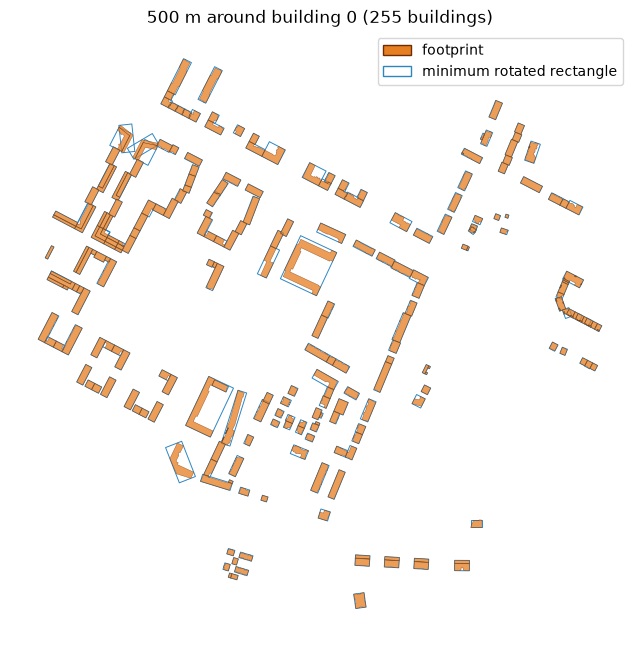

In [20]:
import shapely
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

building_id = torino_residenziale_express["building_id"].iloc[0]
center = torino_residenziale_express.loc[
    torino_residenziale_express["building_id"].eq(building_id),
    "lod0_footprint_32632",
].iloc[0].centroid

near = shapely.distance(
    torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
    center,
) <= 500
block = torino_residenziale_express.loc[near]

rectangles = gpd.GeoSeries(block["minimum_rotated_rectangle"].to_numpy(), crs="EPSG:32632")
footprints = gpd.GeoSeries(block["lod0_footprint_32632"].to_numpy(), crs="EPSG:32632")

ax = rectangles.plot(facecolor="none", edgecolor="#2E86C1", linewidth=0.7, figsize=(8, 8))
footprints.plot(ax=ax, facecolor="#E67E22", edgecolor="#6E2C00", alpha=0.75, linewidth=0.3)
ax.legend(handles=[
    Patch(facecolor="#E67E22", edgecolor="#6E2C00", label="footprint"),
    Patch(facecolor="none", edgecolor="#2E86C1", label="minimum rotated rectangle"),
])
ax.set_title(f"500 m around building {building_id} ({len(block)} buildings)")
ax.set_axis_off()
plt.show()

In [21]:
torino_residenziale_express["footprint_area_m2"] = shapely.area(
    torino_residenziale_express["lod0_footprint_32632"].to_numpy()
)
torino_residenziale_express["rectangle_area_m2"] = shapely.area(
    torino_residenziale_express["minimum_rotated_rectangle"].to_numpy()
)

In [22]:
torino_residenziale_express["area_difference_m2"] = (
    torino_residenziale_express["rectangle_area_m2"]
    - torino_residenziale_express["footprint_area_m2"]
)

print(
    torino_residenziale_express[
        ["footprint_area_m2", "rectangle_area_m2", "area_difference_m2"]
    ].describe().round(1)
)

       footprint_area_m2  rectangle_area_m2  area_difference_m2
count            47075.0            47075.0             47075.0
mean               197.8              250.3                52.5
std                202.3              378.3               218.1
min                  0.2                0.4                -0.0
25%                 79.8               88.2                 1.6
50%                145.2              159.9                10.2
75%                246.1              286.7                33.2
max               8394.6            23169.9             16119.3


In [23]:
torino_residenziale_express["rectangle_fill"] = (
    torino_residenziale_express["footprint_area_m2"]
    / torino_residenziale_express["rectangle_area_m2"]
)
torino_residenziale_express["rectangle_well_fitted"] = (
    torino_residenziale_express["rectangle_fill"] >= 0.85
)

In [24]:
import numpy as np

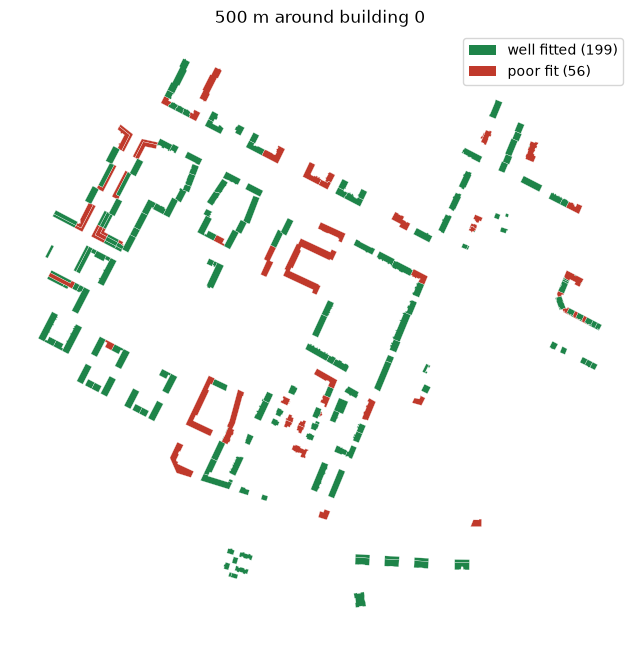

In [32]:
import shapely
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

building_id = torino_residenziale_express["building_id"].iloc[0]
center = torino_residenziale_express.loc[
    torino_residenziale_express["building_id"].eq(building_id),
    "lod0_footprint_32632",
].iloc[0].centroid

near = shapely.distance(
    torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
    center,
) <= 500
block = torino_residenziale_express.loc[near]

footprints = gpd.GeoSeries(block["lod0_footprint_32632"].to_numpy(), crs="EPSG:32632")
fitted_flag = block["rectangle_well_fitted"].fillna(False).to_numpy()
colors = np.where(fitted_flag, "#1E8449", "#C0392B")

ax = footprints.plot(color=colors, edgecolor="white", linewidth=0.2, figsize=(8, 8))
fitted = int(fitted_flag.sum())
ax.legend(handles=[
    Patch(facecolor="#1E8449", label=f"well fitted ({fitted})"),
    Patch(facecolor="#C0392B", label=f"poor fit ({len(block) - fitted})"),
])
ax.set_title(f"500 m around building {building_id}")
ax.set_axis_off()
plt.show()

import plotly.express as px

footprints = gpd.GeoDataFrame(
    {
        "building_id": torino_residenziale_express["building_id"].to_numpy(),
        "rectangle_fill": torino_residenziale_express["rectangle_fill"].round(3).to_numpy(),
        "fit_class": np.where(
            torino_residenziale_express["rectangle_well_fitted"].fillna(False).to_numpy(),
            "well fitted",
            "poor fit",
        ),
    },
    geometry=gpd.GeoSeries(
        torino_residenziale_express["lod0_footprint_32632"].simplify(2).to_numpy(),
        crs="EPSG:32632",
    ).to_crs("EPSG:4326"),
    crs="EPSG:4326",
).reset_index(drop=True)
footprints["fid"] = footprints.index.astype(str)

rectangle_geometry = gpd.GeoSeries(
    torino_residenziale_express["minimum_rotated_rectangle"].to_numpy(),
    crs="EPSG:32632",
).to_crs("EPSG:4326")
rectangles = gpd.GeoDataFrame(geometry=rectangle_geometry, crs="EPSG:4326").reset_index(drop=True)
rectangles["layer"] = "minimum rotated rectangle"
rectangles["fid"] = rectangles.index.astype(str)

minx, miny, maxx, maxy = footprints.total_bounds
figure = px.choropleth_map(
    rectangles,
    geojson=rectangles[["fid", "geometry"]].__geo_interface__,
    locations="fid",
    featureidkey="properties.fid",
    color="layer",
    color_discrete_map={"minimum rotated rectangle": "#2E86C1"},
    opacity=0.35,
    map_style="carto-positron",
    center={"lat": (miny + maxy) / 2, "lon": (minx + maxx) / 2},
    zoom=11,
)
footprint_layer = px.choropleth_map(
    footprints,
    geojson=footprints[["fid", "fit_class", "geometry"]].__geo_interface__,
    locations="fid",
    featureidkey="properties.fid",
    color="fit_class",
    color_discrete_map={"well fitted": "#1E8449", "poor fit": "#C0392B"},
    opacity=0.8,
    hover_data={"building_id": True, "rectangle_fill": True, "fid": False},
)
figure.add_traces(footprint_layer.data)
figure.update_layout(margin=dict(l=0, r=0, t=30, b=0), legend_title_text="layer")
figure

In [25]:
fitted = int(torino_residenziale_express["rectangle_well_fitted"].sum())
print(fitted, "well fitted,", len(torino_residenziale_express) - fitted, "poor fit")

34556 well fitted, 12519 poor fit


In [26]:
import math
import shapely
import pandas as pd
from shapely.geometry import Polygon, LineString

PITCH_DEG = 30.0
RISE = math.tan(math.radians(PITCH_DEG))
DEFAULT_EAVE_M = 9.0


def _four_corners(rect):
    if rect is None or rect.is_empty or rect.geom_type != "Polygon":
        return None
    corners = [(float(x), float(y)) for x, y in list(rect.exterior.coords)[:-1]]
    if len(corners) != 4:
        return None
    return corners


def _gable_halves(corners):
    c0, c1, c2, c3 = corners
    along_01 = math.hypot(c1[0] - c0[0], c1[1] - c0[1])
    along_12 = math.hypot(c2[0] - c1[0], c2[1] - c1[1])
    if along_01 >= along_12:
        width = along_12
        mid_plus = ((c1[0] + c2[0]) / 2, (c1[1] + c2[1]) / 2)
        mid_minus = ((c3[0] + c0[0]) / 2, (c3[1] + c0[1]) / 2)
        halves = [
            ([c0, c1, mid_plus, mid_minus], (c0, c1)),
            ([c2, c3, mid_minus, mid_plus], (c2, c3)),
        ]
    else:
        width = along_01
        mid_plus = ((c2[0] + c3[0]) / 2, (c2[1] + c3[1]) / 2)
        mid_minus = ((c0[0] + c1[0]) / 2, (c0[1] + c1[1]) / 2)
        halves = [
            ([c1, c2, mid_plus, mid_minus], (c1, c2)),
            ([c3, c0, mid_minus, mid_plus], (c3, c0)),
        ]
    return width, halves


def _with_z(points, eave_line, eave_h, half_w):
    eave = LineString(eave_line)
    ring = []
    for x, y in points:
        distance = min(shapely.Point(x, y).distance(eave), half_w)
        ring.append((x, y, eave_h + RISE * distance))
    ring.append(ring[0])
    return ring


def _flat_z(poly, eave_h):
    if poly is None or poly.is_empty:
        return []
    if poly.geom_type == "MultiPolygon":
        faces = []
        for part in poly.geoms:
            faces.extend(_flat_z(part, eave_h))
        return faces
    if poly.geom_type != "Polygon":
        return []
    exterior = [(x, y, eave_h) for x, y in poly.exterior.coords]
    holes = [[(x, y, eave_h) for x, y in ring.coords] for ring in poly.interiors]
    return [Polygon(exterior, holes)]

def _gable_ends(corners, eave_h, ridge_h):
    c0, c1, c2, c3 = corners
    along_01 = math.hypot(c1[0] - c0[0], c1[1] - c0[1])
    along_12 = math.hypot(c2[0] - c1[0], c2[1] - c1[1])
    if along_01 >= along_12:
        ends = (
            (c1, c2, ((c1[0] + c2[0]) / 2, (c1[1] + c2[1]) / 2)),
            (c3, c0, ((c3[0] + c0[0]) / 2, (c3[1] + c0[1]) / 2)),
        )
    else:
        ends = (
            (c0, c1, ((c0[0] + c1[0]) / 2, (c0[1] + c1[1]) / 2)),
            (c2, c3, ((c2[0] + c3[0]) / 2, (c2[1] + c3[1]) / 2)),
        )
    faces = []
    for a, b, ridge in ends:
        faces.append(Polygon([
            (a[0], a[1], eave_h),
            (b[0], b[1], eave_h),
            (ridge[0], ridge[1], ridge_h),
            (a[0], a[1], eave_h),
        ]))
    return faces


records = []
heights = pd.to_numeric(torino_residenziale_express["building_height_m"], errors="coerce").to_numpy()
fitted = torino_residenziale_express["rectangle_well_fitted"].fillna(False).to_numpy()
ids = torino_residenziale_express["building_id"].to_numpy()
footprints = torino_residenziale_express["lod0_footprint_32632"].to_numpy()
rectangles = torino_residenziale_express["minimum_rotated_rectangle"].to_numpy()

for building_id, is_fitted, height, footprint, rect in zip(ids, fitted, heights, footprints, rectangles):
    eave_h = DEFAULT_EAVE_M if height != height else float(height)
    corners = _four_corners(rect) if is_fitted else None
    if corners is not None:
        width, halves = _gable_halves(corners)
        half_w = width / 2
        ridge_h = eave_h + RISE * half_w
        for face_idx, (points, eave_line) in enumerate(halves):
            records.append({
                "building_id": building_id,
                "face_idx": face_idx,
                "roof_type": "gable",
                "pitch_deg": PITCH_DEG,
                "eave_h": eave_h,
                "ridge_h": ridge_h,
                "geometry": Polygon(_with_z(points, eave_line, eave_h, half_w)),
            })
        for face_idx, face in enumerate(_gable_ends(corners, eave_h, ridge_h), start=2):
            records.append({
                "building_id": building_id,
                "face_idx": face_idx,
                "roof_type": "gable_end",
                "pitch_deg": PITCH_DEG,
                "eave_h": eave_h,
                "ridge_h": ridge_h,
                "geometry": face,
            })
        continue
    for face_idx, face in enumerate(_flat_z(footprint, eave_h)):
        records.append({
            "building_id": building_id,
            "face_idx": face_idx,
            "roof_type": "flat",
            "pitch_deg": 0.0,
            "eave_h": eave_h,
            "ridge_h": eave_h,
            "geometry": face,
        })

roofs = gpd.GeoDataFrame(records, geometry="geometry", crs="EPSG:32632")
print(roofs.groupby("roof_type")["building_id"].nunique().to_dict(), "faces", len(roofs))

{'flat': 12519, 'gable': 34556, 'gable_end': 34556} faces 150743


In [36]:
import shapely
from shapely.ops import triangulate
import plotly.graph_objects as go

radius_m = 20
building_id = torino_residenziale_express["building_id"].iloc[0]
center = torino_residenziale_express.loc[
    torino_residenziale_express["building_id"].eq(building_id),
    "lod0_footprint_32632",
].iloc[0].centroid

near = shapely.distance(
    torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
    center,
) <= radius_m
block = torino_residenziale_express.loc[near].copy()
block["eave_h"] = (
    pd.to_numeric(block["building_height_m"], errors="coerce").fillna(9.0)
)
block_ids = set(block["building_id"])
block_roofs = roofs.loc[roofs["building_id"].isin(block_ids)]
print(
    len(block), "buildings,",
    block_roofs.loc[block_roofs["roof_type"].eq("gable"), "building_id"].nunique(),
    "with a gable",
)


def add_triangles(bucket, triangles):
    x, y, z, i, j, k = bucket
    for (x0, y0, z0), (x1, y1, z1), (x2, y2, z2) in triangles:
        base = len(x)
        x.extend((x0, x1, x2))
        y.extend((y0, y1, y2))
        z.extend((z0, z1, z2))
        i.append(base)
        j.append(base + 1)
        k.append(base + 2)


def wall_triangles(poly, eave_h):
    triangles = []
    rings = [poly.exterior, *poly.interiors] if poly.geom_type == "Polygon" else [
        ring for part in poly.geoms for ring in (part.exterior, *part.interiors)
    ]
    for ring in rings:
        coords = list(ring.coords)[:-1]
        for a, b in zip(coords, coords[1:] + coords[:1]):
            p0 = (a[0] - center.x, a[1] - center.y, 0.0)
            p1 = (b[0] - center.x, b[1] - center.y, 0.0)
            p2 = (b[0] - center.x, b[1] - center.y, eave_h)
            p3 = (a[0] - center.x, a[1] - center.y, eave_h)
            triangles.append((p0, p1, p2))
            triangles.append((p0, p2, p3))
    return triangles


def face_triangles(poly):
    # Fan the 3D ring. A gable end is vertical, so a flat triangulation drops it.
    raw = shapely.get_coordinates(poly, include_z=True)[:-1]
    points = []
    for x, y, z in raw:
        point = (float(x) - center.x, float(y) - center.y, float(z))
        if points and max(abs(point[k] - points[-1][k]) for k in range(3)) < 1e-6:
            continue
        points.append(point)
    triangles = []
    for n in range(1, len(points) - 1):
        triangles.append((points[0], points[n], points[n + 1]))
        triangles.append((points[0], points[n + 1], points[n]))
    return triangles


buckets = {name: ([], [], [], [], [], []) for name in ("walls", "gable", "gable_end", "flat")}
for row in block.itertuples(index=False):
    add_triangles(buckets["walls"], wall_triangles(row.lod0_footprint_32632, row.eave_h))
for row in block_roofs.itertuples(index=False):
    add_triangles(buckets[row.roof_type], face_triangles(row.geometry))

figure = go.Figure()
for name, color in (
    ("walls", "#F5F0E6"),
    ("gable", "#C0392B"),
    ("gable_end", "#E67E22"),
    ("flat", "#95A5A6"),
):
    x, y, z, i, j, k = buckets[name]
    if not x:
        continue
    figure.add_trace(go.Mesh3d(
        x=x, y=y, z=z, i=i, j=j, k=k,
        color=color, name=name, flatshading=True,
    ))
figure.update_layout(
    scene=dict(aspectmode="data"),
    margin=dict(l=0, r=0, t=30, b=0),
    title=f"{radius_m:.0f} m around building {building_id}",
)
figure

1 buildings, 1 with a gable


### Opennings

In [28]:
import re
from shapely.ops import substring

def story_count(raw):
    above, extra = re.fullmatch(r"(\d+)(?:\+(\d+|s))?", str(raw).strip().lower()).groups()
    if extra is None or extra == "s":
        return max(int(above), 1)
    return max(int(above) + int(extra), 1)


ids = torino_residenziale_express["building_id"].to_numpy()
ground = pd.to_numeric(torino_residenziale_express["ground_elevation_m"], errors="coerce")
height = pd.to_numeric(torino_residenziale_express["building_height_m"], errors="coerce")
eave = pd.to_numeric(torino_residenziale_express["eave_elevation_m"], errors="coerce")
z_ground_of = pd.Series(ground.to_numpy(), index=ids).groupby(level=0).first()
z_eave_of = pd.Series(eave.fillna(ground + height).to_numpy(), index=ids).groupby(level=0).first()
story_n = (
    torino_residenziale_express[["building_id", "floor_count_raw"]]
    .drop_duplicates("building_id")
    .set_index("building_id")["floor_count_raw"]
    .map(story_count)
)


def floor_bands(building_id):
    z0 = z_ground_of.get(building_id)
    z1 = z_eave_of.get(building_id)
    if z0 is None or z1 is None or z0 != z0 or z1 != z1 or not z1 > z0:
        return []
    n_floors = int(story_n.get(building_id, 1))
    step = (float(z1) - float(z0)) / n_floors
    return [(float(z0) + i * step, float(z0) + (i + 1) * step, i) for i in range(n_floors)]


def band(row, wall_class, line, z0, z1, floor_index):
    piece_height = z1 - z0
    piece_length = float(line.length)
    return {
        "building_id": row.building_id,
        "wall_id": row.wall_id,
        "is_courtyard": row.is_courtyard,
        "azimuth_deg": row.azimuth_deg,
        "length_m": piece_length,
        "z_bottom": z0,
        "z_top": z1,
        "height_m": piece_height,
        "area_m2": piece_length * piece_height,
        "wall_class": wall_class,
        "neighbor_building_id": row.neighbor_building_id,
        "floor_index": floor_index,
        "geometry": line,
    }


records = []
for row in wall_classes.itertuples(index=False):
    if row.wall_class == "party":
        records.append(band(row, "party", row.geometry, float(row.z_bottom), float(row.z_top), -1))
        continue
    line = row.geometry
    length = float(line.length)
    n_openings = int(length // 5)
    for z0, z1, floor_index in floor_bands(row.building_id):
        lo = max(float(row.z_bottom), z0)
        hi = min(float(row.z_top), z1)
        floor_height = hi - lo
        if floor_height < 0.05:
            continue
        if n_openings < 1 or length < 0.05:
            records.append(band(row, "exposed_opaque", line, lo, hi, floor_index))
            continue
        open_height = floor_height * 0.9
        open_bottom = lo + (floor_height - open_height) / 2
        open_top = open_bottom + open_height
        open_width = (0.2 / 0.9) * length / n_openings
        bay = length / n_openings
        for i in range(n_openings):
            bay_start = i * bay
            bay_end = (i + 1) * bay
            opening_start = bay_start + (bay - open_width) / 2
            opening_end = opening_start + open_width
            opening = substring(line, opening_start, opening_end)
            records.append(band(row, "exposed_opaque", substring(line, bay_start, opening_start), lo, hi, floor_index))
            records.append(band(row, "exposed_opaque", opening, lo, open_bottom, floor_index))
            records.append(band(row, "exposed_opening", opening, open_bottom, open_top, floor_index))
            records.append(band(row, "exposed_opaque", opening, open_top, hi, floor_index))
            records.append(band(row, "exposed_opaque", substring(line, opening_end, bay_end), lo, hi, floor_index))

facades = gpd.GeoDataFrame(records, geometry="geometry", crs="EPSG:32632")
facades = facades.loc[facades["height_m"] >= 0.05].reset_index(drop=True)
openings = facades.loc[facades["wall_class"].eq("exposed_opening")].copy()
print(len(openings), "openings across", openings["building_id"].nunique(), "buildings")

1352809 openings across 42117 buildings


In [31]:
import plotly.graph_objects as go

COLOR = {
    "exposed_opening": "#2E86C1",
    "party": "#7F8C8D",
    "exposed_opaque": "#E67E22",
}


def wall_figure(portion):
    origin = shapely.centroid(shapely.union_all(portion.geometry.to_numpy()))
    origin_z = float(portion["z_bottom"].min())
    figure = go.Figure()
    for wall_class, color in COLOR.items():
        pieces = portion.loc[portion["wall_class"] == wall_class]
        x, y, z, i, j, k, hover = [], [], [], [], [], [], []
        for piece in pieces.itertuples(index=False):
            coordinates = shapely.get_coordinates(piece.geometry)
            start, end = coordinates[0], coordinates[-1]
            base = len(x)
            x0, y0 = start[0] - origin.x, start[1] - origin.y
            x1, y1 = end[0] - origin.x, end[1] - origin.y
            z0 = float(piece.z_bottom) - origin_z
            z1 = float(piece.z_top) - origin_z
            x.extend([x0, x0, x1, x1])
            y.extend([y0, y0, y1, y1])
            z.extend([z0, z1, z1, z0])
            i.extend([base, base, base, base])
            j.extend([base + 1, base + 2, base + 2, base + 3])
            k.extend([base + 2, base + 3, base + 1, base + 2])
            label = (
                f"{wall_class}<br>building {piece.building_id}"
                f"<br>{piece.area_m2:.0f} m²"
            )
            hover.extend([label] * 4)
        if not x:
            continue
        figure.add_trace(go.Mesh3d(
            x=x, y=y, z=z, i=i, j=j, k=k,
            color=color,
            name=wall_class,
            hovertext=hover,
            hoverinfo="text",
            flatshading=True,
        ))
    figure.update_layout(
        scene=dict(aspectmode="data"),
        legend_title_text="wall class",
        margin=dict(l=0, r=0, t=30, b=0),
    )
    return figure


building_id = torino_residenziale_express["building_id"].iloc[1000]
center = torino_residenziale_express.loc[
    torino_residenziale_express["building_id"].eq(building_id),
    "lod0_footprint_32632",
].iloc[0].centroid
near = shapely.distance(
    torino_residenziale_express["lod0_footprint_32632"].to_numpy(),
    center,
) <= 80
district_ids = set(torino_residenziale_express.loc[near, "building_id"])

portion = facades.loc[facades["building_id"].isin(district_ids)]
district_roofs = roofs.loc[roofs["building_id"].isin(district_ids)]
print(len(district_ids), "buildings,", int((portion["wall_class"] == "exposed_opening").sum()), "openings")

figure = wall_figure(portion)
origin = shapely.centroid(shapely.union_all(portion.geometry.to_numpy()))
origin_z = float(portion["z_bottom"].min())


def ring_triangles(poly, z_shift):
    points = []
    for x, y, z in shapely.get_coordinates(poly, include_z=True)[:-1]:
        point = (float(x) - origin.x, float(y) - origin.y, float(z) + z_shift - origin_z)
        if points and max(abs(point[k] - points[-1][k]) for k in range(3)) < 1e-6:
            continue
        points.append(point)
    triangles = []
    for n in range(1, len(points) - 1):
        triangles.append((points[0], points[n], points[n + 1]))
        triangles.append((points[0], points[n + 1], points[n]))
    return triangles


roof_color = {"gable": "#C0392B", "gable_end": COLOR["exposed_opaque"], "flat": "#95A5A6"}
for roof_type, color in roof_color.items():
    faces = district_roofs.loc[district_roofs["roof_type"].eq(roof_type)]
    x, y, z, i, j, k = [], [], [], [], [], []
    for row in faces.itertuples(index=False):
        z_eave = z_eave_of.get(row.building_id)
        if z_eave is None or z_eave != z_eave:
            continue
        z_shift = float(z_eave) - float(row.eave_h)
        for tri in ring_triangles(row.geometry, z_shift):
            base = len(x)
            for px, py, pz in tri:
                x.append(px)
                y.append(py)
                z.append(pz)
            i.append(base)
            j.append(base + 1)
            k.append(base + 2)
    if x:
        figure.add_trace(go.Mesh3d(
            x=x, y=y, z=z, i=i, j=j, k=k,
            color=color, name=roof_type, flatshading=True,
        ))

figure.update_layout(title=f"80 m around building {building_id}")
figure

21 buildings, 571 openings
